Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

Load Upload the Data

In [ ]:

df = pd.read_csv("/content/crop_yield_dataset_noisy.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (36520, 12)


,Date,Crop_Type,Soil_Type,Soil_pH,Temperature,Humidity,Wind_Speed,N,P,K,Crop_Yield,Soil_Quality
0,2014-01-01,Wheat,Peaty,5.618131,9.010582,79.616245,10.310642,59.171685,45.268164,30.371699,0.000000,22.833333
1,2014-01-01,Corn,Loamy,6.508358,20.899665,80.000000,8.345089,83.733716,64.625806,51.021184,110.687443,66.666667
2,2014-01-01,Rice,Peaty,5.526695,12.030975,80.000000,7.457723,71.208223,56.412747,37.845092,0.000000,27.333333
3,2014-01-01,Barley,Sandy,6.842846,20.236216,80.000000,2.268132,50.568213,40.549231,30.589252,46.754111,35.000000
4,2014-01-01,Soybean,Peaty,5.567338,16.677721,80.000000,7.357503,49.830983,44.939648,38.339475,32.296047,22.166667


Inspect Colums and Datatypes

In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Columns:
['Date', 'Crop_Type', 'Soil_Type', 'Soil_pH', 'Temperature', 'Humidity', 'Wind_Speed', 'N', 'P', 'K', 'Crop_Yield', 'Soil_Quality']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36520 entries, 0 to 36519
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          36520 non-null  object 
 1   Crop_Type     36520 non-null  object 
 2   Soil_Type     36520 non-null  object 
 3   Soil_pH       36520 non-null  float64
 4   Temperature   36520 non-null  float64
 5   Humidity      36520 non-null  float64
 6   Wind_Speed    36520 non-null  float64
 7   N             36520 non-null  float64
 8   P             36520 non-null  float64
 9   K             36520 non-null  float64
 10  Crop_Yield    36520 non-null  float64
 11  Soil_Quality  36520 non-null  float64
dtypes: float64(9), object(3)
memory usage: 3.3+ MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,36520,3652,2023-12-31,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Type,36520,10,Wheat,3652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,36520,5,Saline,7361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_pH,36520.0,NaN,NaN,NaN,6.602645,0.800183,5.5,6.194395,6.498853,6.807623,8.0
Temperature,36520.0,NaN,NaN,NaN,23.811287,8.964593,-3.540176,17.176125,22.91739,30.280069,54.148911
Humidity,36520.0,NaN,NaN,NaN,74.152529,6.707596,46.325265,69.735692,77.094954,79.786646,80.0
Wind_Speed,36520.0,NaN,NaN,NaN,10.023317,3.012837,0.0,7.981359,10.006492,12.048931,22.606078
N,36520.0,NaN,NaN,NaN,65.998481,10.887972,45.0,58.031484,65.300598,72.352012,91.0
P,36520.0,NaN,NaN,NaN,53.010262,8.807959,36.0,45.510902,53.470421,59.944818,72.0
K,36520.0,NaN,NaN,NaN,42.017027,8.527069,27.0,35.183243,41.425683,48.885318,60.0


Check Data Quality

In [ ]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("Exact duplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

print("\nTarget summary:")
display(df["Crop_Yield"].describe())

print("\nZero-yield records:", (df["Crop_Yield"] == 0).sum())
print("Negative-yield records:", (df["Crop_Yield"] < 0).sum())

print("\nNegative wind speeds:", (df["Wind_Speed"] < 0).sum())

Missing values:


,Missing Count
Date,0
Crop_Type,0
Soil_Type,0
Soil_pH,0
Temperature,0
Humidity,0
Wind_Speed,0
N,0
P,0
K,0


Exact duplicate rows: 0

Unique values per column:


,Unique Values
Date,3652
Crop_Type,10
Soil_Type,5
Soil_pH,29210
Temperature,36519
Humidity,29265
Wind_Speed,36504
N,35453
P,35489
K,35086



Target summary:


,Crop_Yield
count,36520.000000
mean,26.895134
std,25.919112
min,0.000000
25%,0.000000
50%,23.332071
75%,46.134489
max,141.423319



Zero-yield records: 11025
Negative-yield records: 0

Negative wind speeds: 0


check data range and record pattern

In [ ]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Invalid dates:", df["Date"].isna().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Unique dates:", df["Date"].nunique())

records_per_day = df.groupby("Date").size()

print("\nRecords per day:")
display(records_per_day.value_counts().sort_index().to_frame("Number of Days"))

print("\nRecords per crop:")
display(df["Crop_Type"].value_counts().to_frame("Record Count"))

Invalid dates: 0
Date range: 2014-01-01 00:00:00 to 2023-12-31 00:00:00
Unique dates: 3652

Records per day:


,Number of Days
10,3652



Records per crop:


,Record Count
Crop_Type,
Wheat,3652
Corn,3652
Rice,3652
Barley,3652
Soybean,3652
Cotton,3652
Sugarcane,3652
Tomato,3652
Potato,3652


Explore Crop Yield

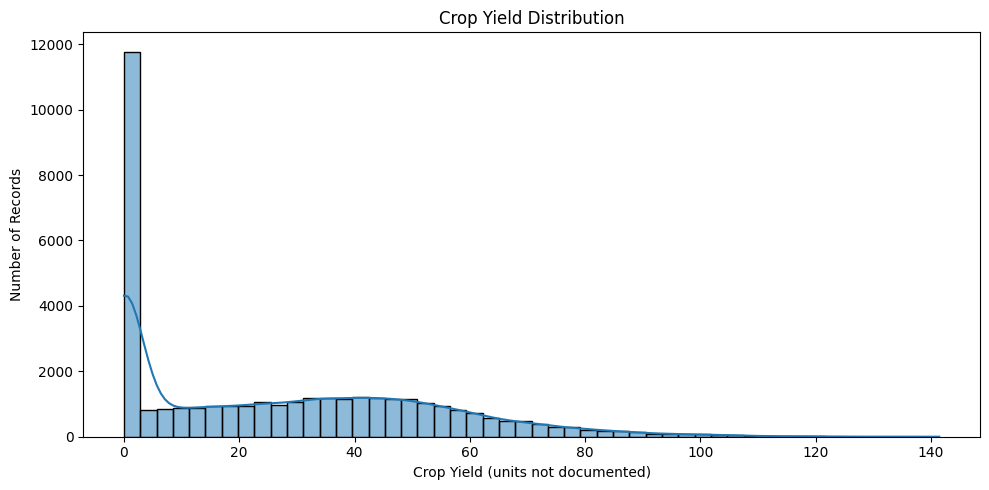

Yield statistics by crop:


,count,mean,median,min,max
Crop_Type,,,,,
Barley,3652,25.62,22.78,0.0,106.53
Corn,3652,28.33,25.01,0.0,121.55
Cotton,3652,29.24,25.78,0.0,120.29
Potato,3652,26.18,23.98,0.0,115.01
Rice,3652,28.79,23.43,0.0,127.90
Soybean,3652,25.93,24.60,0.0,112.88
Sugarcane,3652,28.71,23.30,0.0,141.42
Sunflower,3652,27.50,24.48,0.0,118.76
Tomato,3652,22.82,18.14,0.0,104.07


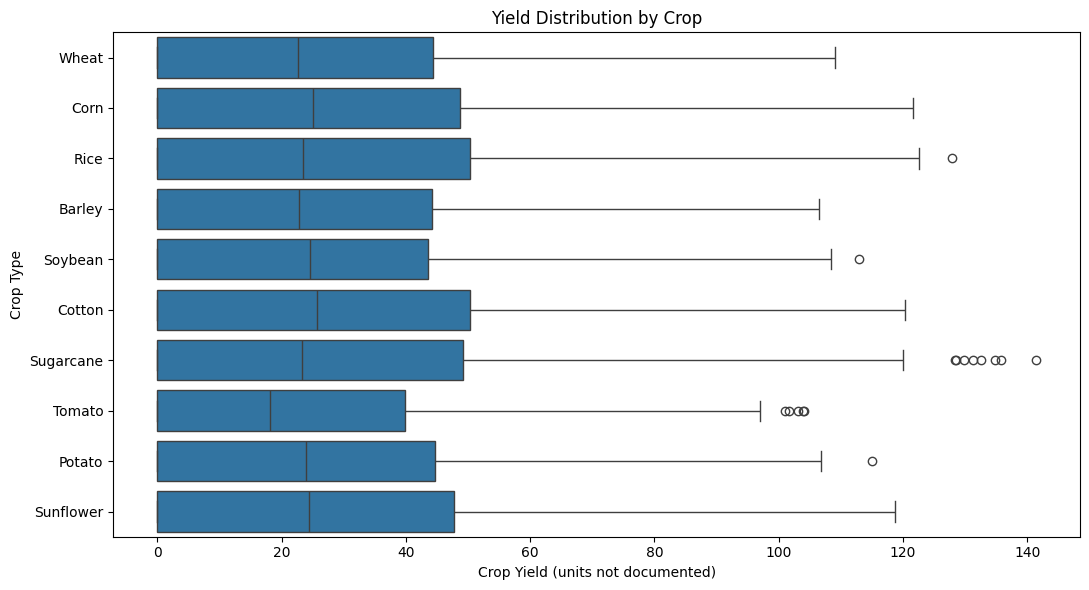

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Crop_Yield"], bins=50, kde=True)

plt.title("Crop Yield Distribution")
plt.xlabel("Crop Yield (units not documented)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Yield statistics by crop:")

display(
    df.groupby("Crop_Type")["Crop_Yield"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Crop_Yield",
    y="Crop_Type"
)

plt.title("Yield Distribution by Crop")
plt.xlabel("Crop Yield (units not documented)")
plt.ylabel("Crop Type")
plt.tight_layout()
plt.show()

Prepare data

In [ ]:
df_model = df.dropna(
    subset=["Date", "Crop_Yield"]
).copy()

# Investigate negative target values rather than silently accepting them.
if (df_model["Crop_Yield"] < 0).any():
    raise ValueError(
        "Negative Crop_Yield values found. Investigate them before training."
    )

# Negative wind speed is physically invalid.
# Convert it to missing so the training pipeline can impute it.
df_model.loc[
    df_model["Wind_Speed"] < 0,
    "Wind_Speed"
] = np.nan

# Extract calendar features.
df_model["Year"] = df_model["Date"].dt.year
df_model["Month"] = df_model["Date"].dt.month
df_model["DayOfYear"] = df_model["Date"].dt.dayofyear

# Cyclical features preserve the fact that December and January are adjacent.
df_model["Month_Sin"] = np.sin(
    2 * np.pi * df_model["Month"] / 12
)
df_model["Month_Cos"] = np.cos(
    2 * np.pi * df_model["Month"] / 12
)
df_model["DayOfYear_Sin"] = np.sin(
    2 * np.pi * df_model["DayOfYear"] / 365.25
)
df_model["DayOfYear_Cos"] = np.cos(
    2 * np.pi * df_model["DayOfYear"] / 365.25
)

print("Prepared dataset shape:", df_model.shape)
print("Missing wind speeds after validation:",
      df_model["Wind_Speed"].isna().sum())

display(df_model.head())

Prepared dataset shape: (36520, 19)
Missing wind speeds after validation: 0


,Date,Crop_Type,Soil_Type,Soil_pH,Temperature,Humidity,Wind_Speed,N,P,K,Crop_Yield,Soil_Quality,Year,Month,DayOfYear,Month_Sin,Month_Cos,DayOfYear_Sin,DayOfYear_Cos
0,2014-01-01,Wheat,Peaty,5.618131,9.010582,79.616245,10.310642,59.171685,45.268164,30.371699,0.000000,22.833333,2014,1,1,0.5,0.866025,0.017202,0.999852
1,2014-01-01,Corn,Loamy,6.508358,20.899665,80.000000,8.345089,83.733716,64.625806,51.021184,110.687443,66.666667,2014,1,1,0.5,0.866025,0.017202,0.999852
2,2014-01-01,Rice,Peaty,5.526695,12.030975,80.000000,7.457723,71.208223,56.412747,37.845092,0.000000,27.333333,2014,1,1,0.5,0.866025,0.017202,0.999852
3,2014-01-01,Barley,Sandy,6.842846,20.236216,80.000000,2.268132,50.568213,40.549231,30.589252,46.754111,35.000000,2014,1,1,0.5,0.866025,0.017202,0.999852
4,2014-01-01,Soybean,Peaty,5.567338,16.677721,80.000000,7.357503,49.830983,44.939648,38.339475,32.296047,22.166667,2014,1,1,0.5,0.866025,0.017202,0.999852


define input Features and Targets

In [ ]:
numeric_features = [
    "Soil_pH",
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "N",
    "P",
    "K",
    "Year",
    "Month_Sin",
    "Month_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos"
]

categorical_features = [
    "Crop_Type",
    "Soil_Type"
]

feature_columns = numeric_features + categorical_features

X = df_model[feature_columns].copy()
y = df_model["Crop_Yield"].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(feature_columns)

display(X.head())

Input shape: (36520, 14)
Target shape: (36520,)

Features used:
['Soil_pH', 'Temperature', 'Humidity', 'Wind_Speed', 'N', 'P', 'K', 'Year', 'Month_Sin', 'Month_Cos', 'DayOfYear_Sin', 'DayOfYear_Cos', 'Crop_Type', 'Soil_Type']


,Soil_pH,Temperature,Humidity,Wind_Speed,N,P,K,Year,Month_Sin,Month_Cos,DayOfYear_Sin,DayOfYear_Cos,Crop_Type,Soil_Type
0,5.618131,9.010582,79.616245,10.310642,59.171685,45.268164,30.371699,2014,0.5,0.866025,0.017202,0.999852,Wheat,Peaty
1,6.508358,20.899665,80.000000,8.345089,83.733716,64.625806,51.021184,2014,0.5,0.866025,0.017202,0.999852,Corn,Loamy
2,5.526695,12.030975,80.000000,7.457723,71.208223,56.412747,37.845092,2014,0.5,0.866025,0.017202,0.999852,Rice,Peaty
3,6.842846,20.236216,80.000000,2.268132,50.568213,40.549231,30.589252,2014,0.5,0.866025,0.017202,0.999852,Barley,Sandy
4,5.567338,16.677721,80.000000,7.357503,49.830983,44.939648,38.339475,2014,0.5,0.866025,0.017202,0.999852,Soybean,Peaty


split the data

In [ ]:
df_model = df_model.sort_values("Date").reset_index(drop=True)

unique_dates = np.sort(df_model["Date"].unique())

if len(unique_dates) < 2:
    raise ValueError("Not enough distinct dates for a chronological split.")

split_index = int(len(unique_dates) * 0.80)
split_index = min(max(split_index, 1), len(unique_dates) - 1)

cutoff_date = unique_dates[split_index]

train_df = df_model[df_model["Date"] < cutoff_date].copy()
test_df = df_model[df_model["Date"] >= cutoff_date].copy()

X_train = train_df[feature_columns]
y_train = train_df["Crop_Yield"]

X_test = test_df[feature_columns]
y_test = test_df["Crop_Yield"]

print("Cutoff date:", cutoff_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting date range:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Cutoff date: 2021-12-31T00:00:00.000000000
Training records: 29210
Testing records: 7310

Training date range:
2014-01-01 00:00:00 to 2021-12-30 00:00:00

Testing date range:
2021-12-31 00:00:00 to 2023-12-31 00:00:00


Building Preprocessing Pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

yield_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Preprocessing and regression pipeline created.")

Preprocessing and regression pipeline created.


train The Data

In [ ]:
yield_model.fit(X_train, y_train)

print("Crop yield model trained successfully.")

Crop yield model trained successfully.


Evaluate the model

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = yield_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  4.2692
RMSE: 6.6011
R²:   0.9362


Compare with Baseline Model

In [ ]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)
baseline_r2 = r2_score(y_test, baseline_pred)

comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Random Forest"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2": [baseline_r2, r2]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,22.2233,26.1394,-0.0001
1,Random Forest,4.2692,6.6011,0.9362


Plot actual vs predicted yield

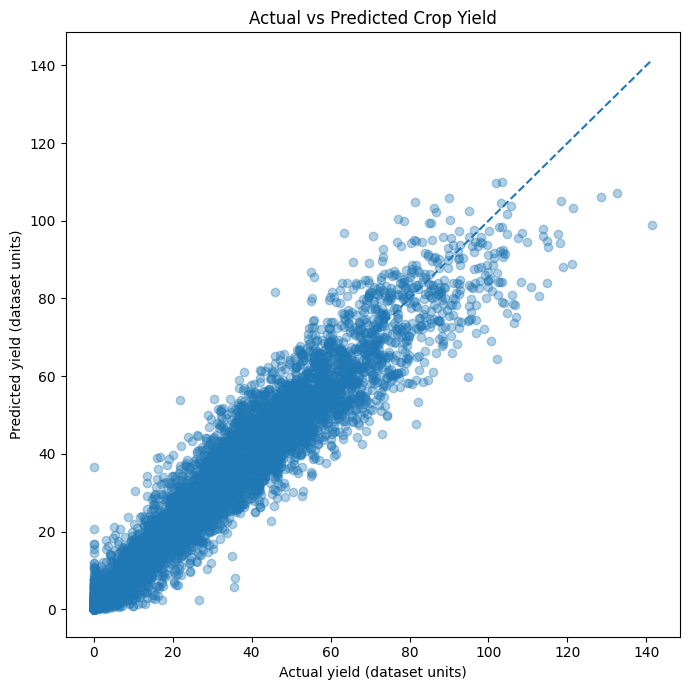

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.35)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual yield (dataset units)")
plt.ylabel("Predicted yield (dataset units)")
plt.title("Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.show()

Inspect the errors

In [ ]:
results = test_df[
    ["Date", "Crop_Type", "Soil_Type", "Crop_Yield"]
].copy()

results["Predicted_Yield"] = y_pred
results["Absolute_Error"] = np.abs(
    results["Crop_Yield"] - results["Predicted_Yield"]
)

display(
    results.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(15)
)

,Date,Crop_Type,Soil_Type,Crop_Yield,Predicted_Yield,Absolute_Error
35500,2023-09-21,Sugarcane,Loamy,141.423319,98.835012,42.588307
32367,2022-11-11,Corn,Loamy,102.163946,64.371073,37.792872
36426,2023-12-22,Rice,Loamy,0.049044,36.488328,36.439284
35649,2023-10-05,Barley,Loamy,45.910771,81.706525,35.795753
35760,2023-10-17,Sunflower,Clay,94.925790,59.679340,35.246449
35922,2023-11-02,Potato,Loamy,81.766580,47.801310,33.965270
32803,2022-12-25,Cotton,Loamy,63.423897,96.857358,33.433461
32985,2023-01-12,Barley,Loamy,106.534867,73.751000,32.783867
33622,2023-03-17,Corn,Loamy,121.150664,88.801425,32.349239
32977,2023-01-11,Soybean,Loamy,112.876016,80.748710,32.127306


Examine Feature Importance

,Feature,Importance
2,numeric__Humidity,0.401020
1,numeric__Temperature,0.309737
23,categorical__Soil_Type_Loamy,0.052837
18,categorical__Crop_Type_Sugarcane,0.043556
16,categorical__Crop_Type_Rice,0.042649
20,categorical__Crop_Type_Tomato,0.041184
5,numeric__P,0.036258
4,numeric__N,0.025675
22,categorical__Soil_Type_Clay,0.014123
3,numeric__Wind_Speed,0.005778


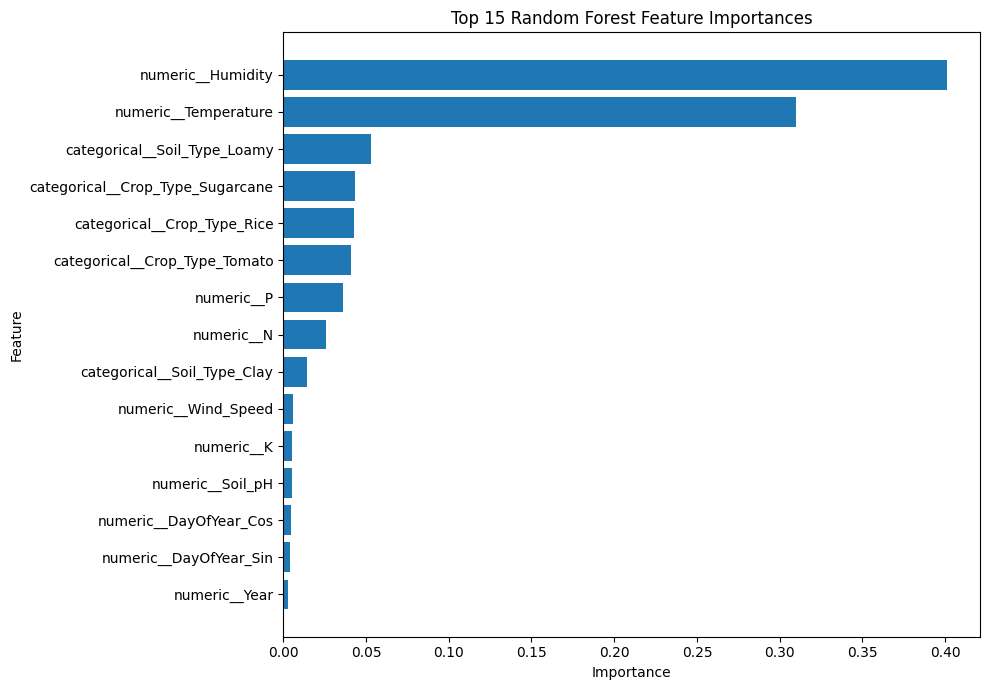

In [ ]:
trained_preprocessor = yield_model.named_steps["preprocessor"]
trained_regressor = yield_model.named_steps["regressor"]

feature_names = trained_preprocessor.get_feature_names_out()
importances = trained_regressor.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Predict Yield for Input

In [ ]:
new_sample = pd.DataFrame([{
    "Soil_pH": 6.5,
    "Temperature": 25.0,
    "Humidity": 70.0,
    "Wind_Speed": 8.0,
    "N": 60.0,
    "P": 40.0,
    "K": 40.0,
    "Year": 2022,
    "Month_Sin": np.sin(2 * np.pi * 7 / 12),
    "Month_Cos": np.cos(2 * np.pi * 7 / 12),
    "DayOfYear_Sin": np.sin(2 * np.pi * 182 / 365.25),
    "DayOfYear_Cos": np.cos(2 * np.pi * 182 / 365.25),
    "Crop_Type": "Wheat",
    "Soil_Type": "Loamy"
}])

prediction = yield_model.predict(new_sample)[0]

print("Predicted crop yield:", round(float(prediction), 3))
print("Units: as represented in the dataset")

Predicted crop yield: 6.522
Units: as represented in the dataset


save the model

In [ ]:
import joblib

model_filename = "agripredict_crop_yield_model.joblib"

joblib.dump(yield_model, model_filename)

print("Model saved successfully:", model_filename)

Model saved successfully: agripredict_crop_yield_model.joblib


reload and test the saved model

In [ ]:
loaded_model = joblib.load(
    "agripredict_crop_yield_model.joblib"
)

reloaded_prediction = loaded_model.predict(new_sample)[0]

print("Original prediction:", round(float(prediction), 4))
print("Reloaded prediction:", round(float(reloaded_prediction), 4))

assert np.isclose(prediction, reloaded_prediction)

print("Saved model verified successfully.")

Original prediction: 6.5221
Reloaded prediction: 6.5221
Saved model verified successfully.


In [ ]:
!pip install -q shap
from export_utils import export_module
cal = ["Month_Sin", "Month_Cos", "DayOfYear_Sin", "DayOfYear_Cos"]
export_module("yield", yield_model, X_train, y_train, X_test, y_test,
              trained_on="crop_yield_dataset_noisy.csv",
              derived=["Year"] + cal, merge={"Season": cal}, importance_rows=40)
!zip -rq yield_export.zip models/yield
from google.colab import files
files.download("yield_export.zip")

dashboard config block: {"metrics": {"r2": 0.9362, "mae": 4.2692, "rmse": 6.6011}, "importance": {"Relative humidity": 0.4492, "Temperature": 0.2383, "Crop type": 0.1348, "Soil type": 0.1075, "Phosphorus": 0.0243, "Nitrogen": 0.0129, "Season": 0.0102, "Soil pH": 0.0095, "Potassium": 0.006, "Wind speed": 0.0052, "Year": 0.0022}}
Exported yield -> models/yield  |  {'mae': 4.2692, 'rmse': 6.6011, 'r2': 0.9362, 'mae_nonzero': 5.9658, 'mae_zero': 0.3464, 'zero_share_test': 0.3019, 'n_train': 29210, 'n_test': 7310}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
print(json.load(open("models/yield/metadata.json"))["importance"][:3])

[{'feature': 'Humidity', 'importance': 0.4492}, {'feature': 'Temperature', 'importance': 0.2383}, {'feature': 'Crop_Type', 'importance': 0.1348}]
